# Market Relationship Intelligence

Explore three evidence categories for directional product relationships. Each candidate requires both an observed exporter role and an observed importer role for the product.

See the [release guide](../docs/TRADE_INTELLIGENCE_RELEASE.md) for the source and validation workflow.

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "notebook_support.py").is_file())
sys.path.insert(0, str(root / "notebooks"))
from notebook_support import BLUE, GOLD, TEAL, bar_chart, load_release, top

manifest, data = load_release('market_opportunity_summary')
year = manifest["year"]
display(Markdown(f"**Dataset year:** {year}  |  **Release:** `{manifest['release_id']}`"))


**Dataset year:** 2024  |  **Release:** `ti-3349f6e0cb6dde75fe7d5323af71463748cad3232bc7bcb476c6ff6dcd8cd41b`

## Charts

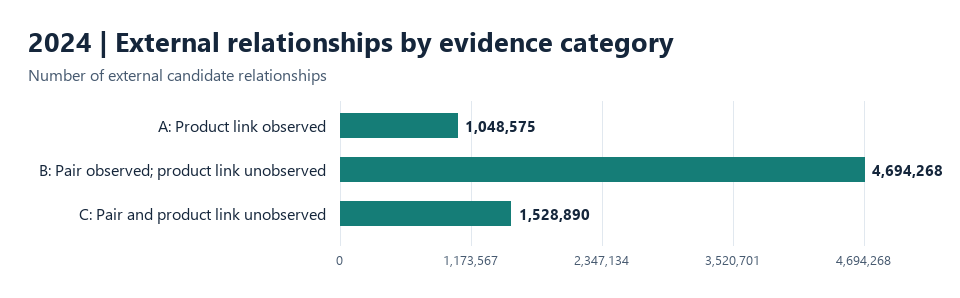

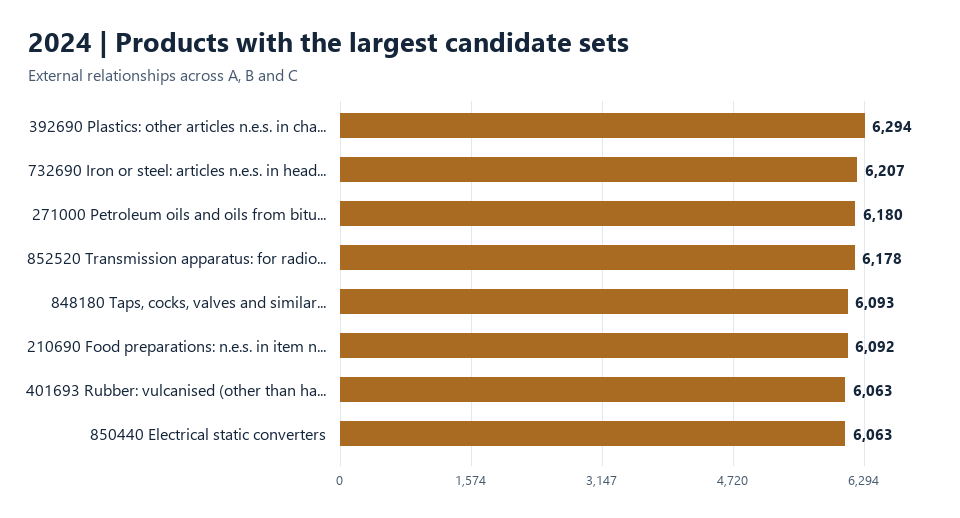

In [2]:
universe = data["universe"]
counts = universe["category_counts"]
categories = [
    ("A: Product link observed", counts["A"]),
    ("B: Pair observed; product link unobserved", counts["B"]),
    ("C: Pair and product link unobserved", counts["C"]),
]
display(bar_chart(f"{year} | External relationships by evidence category",
                  "Number of external candidate relationships", categories, TEAL))

rows = data["products"]
largest = top(rows, "external_relationships", lambda r: r["product_code"])
display(bar_chart(f"{year} | Products with the largest candidate sets", "External relationships across A, B and C",
                  [(f'{r["product_code"]}  {r["description"]}', r["external_relationships"])
                   for r in largest], GOLD))


## Analysis

In [3]:
total = universe["external_relationships"]
assert sum(counts.values()) == total
assert universe["gross_combinations"] - universe["same_market_exclusions"] == total
leader = largest[0]
display(Markdown(f'''
### What the charts show
- **{total:,}** external relationships remain after excluding **{universe["same_market_exclusions"]:,}** same-market combinations from the gross set.
- Category **A** represents **{counts["A"] / total:.1%}**, **B** represents **{counts["B"] / total:.1%}**, and **C** represents **{counts["C"] / total:.1%}**, each measured against all external relationships. B and C reflect observed product roles with varying pair evidence. They provide candidate contexts for review.
- **`{leader["product_code"]}`** ({leader["description"]}) has the largest candidate set at **{leader["external_relationships"]:,}** relationships, including **{leader["category_counts"]["A"]:,}** directly observed links. A large set can result from broad observed exporter and importer coverage. The chart does not estimate profitability, demand, or success probability.
'''))



### What the charts show
- **7,271,733** external relationships remain after excluding **40,474** same-market combinations from the gross set.
- Category **A** represents **14.4%**, **B** represents **64.6%**, and **C** represents **21.0%**, each measured against all external relationships. B and C reflect observed product roles with varying pair evidence. They provide candidate contexts for review.
- **`392690`** (Plastics: other articles n.e.s. in chapter 39) has the largest candidate set at **6,294** relationships, including **1,738** directly observed links. A large set can result from broad observed exporter and importer coverage. The chart does not estimate profitability, demand, or success probability.


### Reading the results

The single-year export reached Excel's worksheet limit and has partial geographic coverage. Record counts measure observed keys in the extract. Currency, trade-value scale, quantity units and HS revision remain unverified. These charts use neither trade values nor quantities. Missing observations provide no evidence of market absence, and the extract cannot establish trends or future demand.
